In [1]:
%load_ext autoreload
%autoreload 2
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from CrocoDash.topo import Topo
from CrocoDash.grid import Grid
from regional_mom6 import regridding as rgd


In [2]:
ds = xr.open_dataset("/glade/derecho/scratch/manishrv/archive/marbl.bio.croc.3/ocn/hist/marbl.bio.croc.3.mom6.h.bgc.z.2000-01.nc")

In [ ]:
vars_below_minus_100 = []

for var in ds.data_vars:
    if (ds[var] < -1e10).any():
        vars_below_minus_100.append(var)

print(vars_below_minus_100)

KeyboardInterrupt: 

In [6]:
s

NameError: name 's' is not defined

In [4]:
v

NameError: name 'v' is not defined

In [2]:
sfc = xr.open_dataset("~/scratch/bgc/eleven-mo-error-res/marbl.bio.croc.3.mom6.h.sfc.2000-01.nc")

grid = Grid.from_supergrid("/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_hgrid.nc")
topo = Topo.from_topo_file(grid,"/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_topo.nc", min_depth = 5)

In [8]:
bgc_fixed_fill = xr.open_dataset("/glade/derecho/scratch/manishrv/bgc/fixed_fill.z.nc")
sfc_file = xr.open_dataset("/glade/derecho/scratch/manishrv/bgc/sfc_phys_fields_south_filled.nc")
one_mo_res = xr.open_dataset("/glade/derecho/scratch/manishrv/bgc/fixed_south_with_actual_negative_fill.nc")

dic_south_boundary = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/processed_interpolated_filled_data/DIC_obc_segment_001.nc")
dic_north_boundary = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/processed_interpolated_filled_data/DIC_obc_segment_002.nc")
dic_east_boundary = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/processed_interpolated_filled_data/DIC_obc_segment_003.nc")

In [4]:
def plot(data):
    masked = xr.where((data != data.min()), data, np.nan)

    masked.plot()
    plt.show()

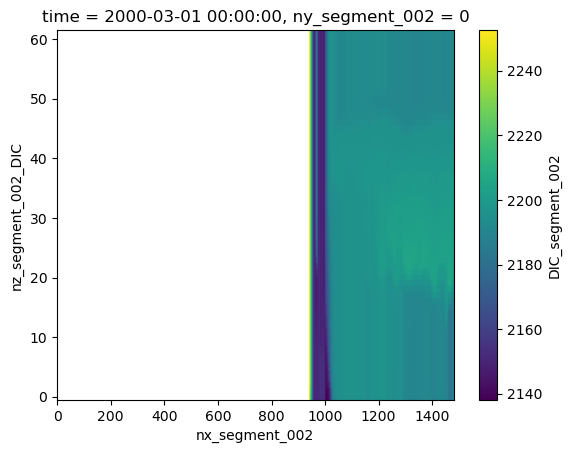

In [6]:
plot(data = dic_north_boundary.DIC_segment_002[1])


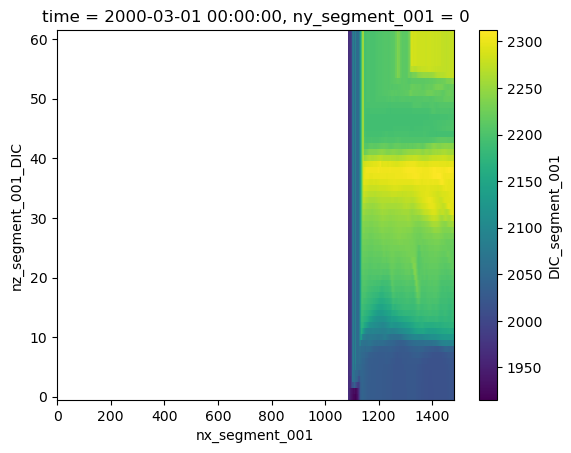

In [20]:
plot(data = dic_south_boundary.DIC_segment_001[1])

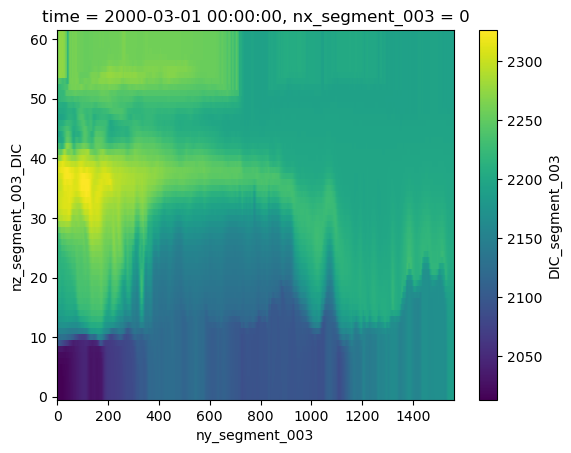

In [19]:
plot(data = dic_east_boundary.DIC_segment_003[1])

In [ ]:
from collections import defaultdict
time_i, depth_i, y_i, x_i = np.where(one_mo_res["DIC"] < 1200)

# Get all (y, x) pairs
yx_pairs = list(zip(y_i, x_i))

# Get unique (y, x) pairs using a set
unique_yx_pairs = set(yx_pairs)
# Map each (y, x) to a set of times and a set of depths
yx_to_times = defaultdict(set)
yx_to_depths = defaultdict(set)

for t, z, y, x in zip(time_i, depth_i, y_i, x_i):
    yx_to_times[(y, x)].add(t)
    yx_to_depths[(y, x)].add(z)

# Print all unique (y, x) locations and their associated times and depths
for (y, x) in sorted(yx_to_times.keys()):
    times = sorted(yx_to_times[(y, x)])
    depths = sorted(yx_to_depths[(y, x)])
    print(f"(y={y}, x={x}):")
    print(f"  Times: {times}")
    print(f"  Depths: {depths}")

(y=0, x=586):
  Times: [1]
  Depths: [11]
(y=0, x=605):
  Times: [4]
  Depths: [22]
(y=0, x=606):
  Times: [2, 3, 4]
  Depths: [22, 23, 24, 25]
(y=0, x=607):
  Times: [1, 2]
  Depths: [22, 23, 24, 25]
(y=0, x=638):
  Times: [6]
  Depths: [24]
(y=0, x=639):
  Times: [4, 5]
  Depths: [24]
(y=0, x=640):
  Times: [4]
  Depths: [24]
(y=0, x=641):
  Times: [3]
  Depths: [24]
(y=0, x=660):
  Times: [2]
  Depths: [14]
(y=0, x=661):
  Times: [2, 3]
  Depths: [14]
(y=0, x=662):
  Times: [3, 4]
  Depths: [14, 15]
(y=0, x=669):
  Times: [2]
  Depths: [9]
(y=0, x=676):
  Times: [1]
  Depths: [5]
(y=0, x=677):
  Times: [1]
  Depths: [0, 1, 4, 5]
(y=0, x=678):
  Times: [1]
  Depths: [0, 1, 2, 3, 4, 5, 6]
(y=0, x=679):
  Times: [1]
  Depths: [0, 1, 2, 3, 4, 5, 6]
(y=0, x=680):
  Times: [1]
  Depths: [0, 1, 2, 3]
(y=0, x=681):
  Times: [1]
  Depths: [3]
(y=0, x=682):
  Times: [2]
  Depths: [27]
(y=0, x=692):
  Times: [7]
  Depths: [24]
(y=0, x=693):
  Times: [5, 6, 7]
  Depths: [24]
(y=0, x=694):
  Tim

In [13]:
len(x_unique), len(y_unique)

(101, 101)

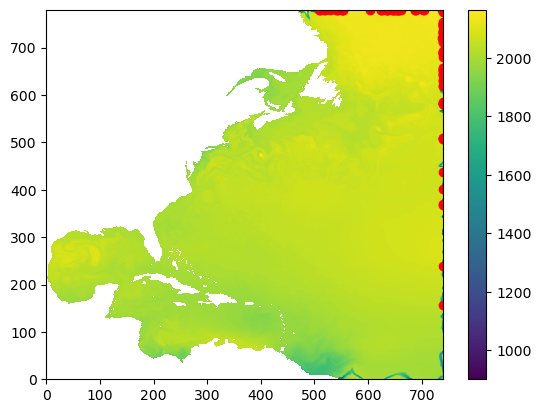

In [10]:
plt.pcolormesh(one_mo_res.DIC[1,0])
plt.colorbar()
plt.scatter(x_unique,y_unique, c="red")


In [19]:
np.unique(search[2][np.where(search[0]==1)])

array([507, 508, 580, 581, 582, 586, 618, 724, 779])

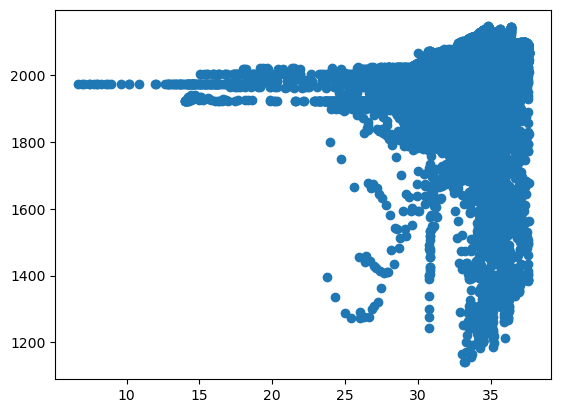

In [44]:
plt.scatter(sfc_file.sos[0],bgc_south_fill.DIC[0,0] )

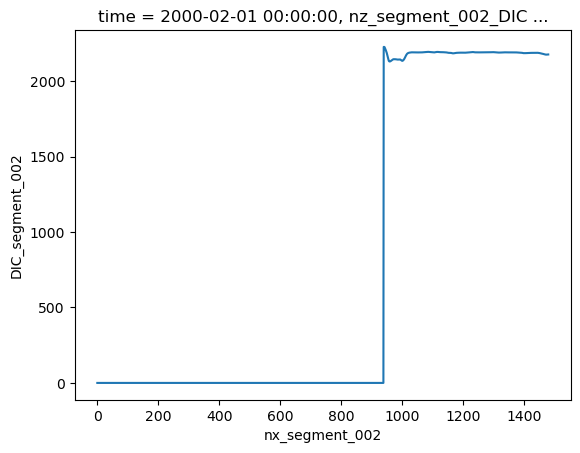

In [26]:
dic_north_boundary.DIC_segment_002[0,0,0,:].plot()

In [20]:
dic_south_boundary.DIC_segment_001[0,0,0,1086:1089].values


array([   0.    , 2003.6636, 2003.6636], dtype=float32)

In [23]:
dic_north_boundary.DIC_segment_002[0,0,0,939:943].values


array([          nan, 2227.13452148, 2227.12963867, 2227.12475586])

In [11]:
second_north = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/fill_major_negative/DIC_obc_segment_002.nc")
second_north.DIC_segment_002[0,0,0,940:943].values


array([          nan, 2227.12963867, 2227.12475586])

In [14]:
fill_negative_sout = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/date_break/DIC_obc_segment_001.nc")
fill_negative_sout.DIC_segment_001[0,0,0,1086:1089].values

array([-1.0000000e+20,  2.0036636e+03,  2.0036636e+03], dtype=float32)

In [56]:
north_mask = rgd.get_boundary_mask(xr.open_dataset("/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_hgrid.nc"),xr.open_dataset("/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_topo.nc"), side="north", segment_name = "segment_002",minimum_depth=9.5,add_land_exceptions=False)
south_mask = rgd.get_boundary_mask(xr.open_dataset("/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_hgrid.nc"),xr.open_dataset("/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_topo.nc"), side="south", segment_name = "segment_001",minimum_depth=9.5,add_land_exceptions=False)

In [57]:
np.where(~np.isnan(south_mask))

(array([1087, 1088, 1089, 1090, 1091, 1092, 1093, 1094, 1095, 1096, 1097,
        1098, 1099, 1100, 1101, 1102, 1103, 1104, 1105, 1106, 1107, 1108,
        1109, 1110, 1111, 1112, 1113, 1114, 1115, 1116, 1117, 1118, 1119,
        1120, 1121, 1122, 1123, 1124, 1125, 1126, 1127, 1128, 1129, 1130,
        1131, 1132, 1133, 1134, 1135, 1136, 1137, 1138, 1139, 1140, 1141,
        1142, 1143, 1144, 1145, 1146, 1147, 1148, 1149, 1150, 1151, 1152,
        1153, 1154, 1155, 1156, 1157, 1158, 1159, 1160, 1161, 1162, 1163,
        1164, 1165, 1166, 1167, 1168, 1169, 1170, 1171, 1172, 1173, 1174,
        1175, 1176, 1177, 1178, 1179, 1180, 1181, 1182, 1183, 1184, 1185,
        1186, 1187, 1188, 1189, 1190, 1191, 1192, 1193, 1194, 1195, 1196,
        1197, 1198, 1199, 1200, 1201, 1202, 1203, 1204, 1205, 1206, 1207,
        1208, 1209, 1210, 1211, 1212, 1213, 1214, 1215, 1216, 1217, 1218,
        1219, 1220, 1221, 1222, 1223, 1224, 1225, 1226, 1227, 1228, 1229,
        1230, 1231, 1232, 1233, 1234, 

In [55]:
bgc_daily = xr.open_dataset("~/scratch/bgc/eleven-mo-error-res/marbl.bio.croc.3.mom6.h.bgc.daily.2000-01.nc")
bgc_z = xr.open_dataset("~/scratch/bgc/eleven-mo-error-res/marbl.bio.croc.3.mom6.h.bgc.z.2000-01.nc")
dic_obc = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/date_break/DIC_obc_segment_002.nc")
bgc_z

<xarray.Dataset>
Dimensions:               (xh: 740, yh: 780, z_l: 35, z_i: 36, time: 1, nbnd: 2)
Coordinates:
  * xh                    (xh) float64 -97.96 -97.88 -97.79 ... -36.46 -36.38
  * yh                    (yh) float64 5.243 5.326 5.409 ... 53.82 53.86 53.89
  * z_l                   (z_l) float64 2.5 10.0 20.0 ... 5.5e+03 6e+03 6.5e+03
  * z_i                   (z_i) float64 0.0 5.0 15.0 ... 6.25e+03 6.75e+03
  * time                  (time) datetime64[ns] 2000-01-19T12:00:00
  * nbnd                  (nbnd) float64 1.0 2.0
Data variables: (12/124)
    so                    (time, z_l, yh, xh) float32 ...
    thetao                (time, z_l, yh, xh) float32 ...
    BOT_FLUX_TO_TEND      (time, z_l, yh, xh) float32 ...
    ALK                   (time, z_l, yh, xh) float32 ...
    DIC                   (time, z_l, yh, xh) float32 ...
    J_DIC                 (time, z_l, yh, xh) float32 ...
    ...                    ...
    volcello              (time, z_l, yh, xh) float32 ...
    h                     (time, z_l, yh, xh) float32 ...
    average_T1            (time) datetime64[ns] ...
    average_T2            (time) datetime64[ns] ...
    average_DT            (time) timedelta64[ns] ...
    time_bounds           (time, nbnd) datetime64[ns] ...
Attributes:
    NumFilesInSet:     1
    title:             MOM6 diagnostic fields table for CESM case: marbl.bio....
    associated_files:  areacello: marbl.bio.croc.3.mom6.h.static.nc
    grid_type:         regular
    grid_tile:         N/A

In [29]:
np.where(topo.tmask.isel(ny=-1))

(array([470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 480, 481, 482,
        483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495,
        496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508,
        509, 510, 511, 512, 513, 514, 515, 516, 517, 518, 519, 520, 521,
        522, 523, 524, 525, 526, 527, 528, 529, 530, 531, 532, 533, 534,
        535, 536, 537, 538, 539, 540, 541, 542, 543, 544, 545, 546, 547,
        548, 549, 550, 551, 552, 553, 554, 555, 556, 557, 558, 559, 560,
        561, 562, 563, 564, 565, 566, 567, 568, 569, 570, 571, 572, 573,
        574, 575, 576, 577, 578, 579, 580, 581, 582, 583, 584, 585, 586,
        587, 588, 589, 590, 591, 592, 593, 594, 595, 596, 597, 598, 599,
        600, 601, 602, 603, 604, 605, 606, 607, 608, 609, 610, 611, 612,
        613, 614, 615, 616, 617, 618, 619, 620, 621, 622, 623, 624, 625,
        626, 627, 628, 629, 630, 631, 632, 633, 634, 635, 636, 637, 638,
        639, 640, 641, 642, 643, 644, 645, 646, 647